# PISA Example Using Public IceCube Data


Dataset must be obtained from the PRD 2023 paper of IceCube

https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/B4RITM&version=1.0

## Setup

Usually you would need to export the location of the data, and the config files to `PISA_RESOURCES`. For this example however, the data is inside our package.

In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/icecube/wg-oscillations-fridge/analysis'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/daemonflux/oscillations_release_2023'

## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This now containes two `Pipelines` in a `DistributionMaker`, one for our neutrinos, and one for the background muons.

In [5]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pisa_settings/pipeline/neutrino_pipeline_daemon_red.cfg"),
    os.path.join(myfiles_path,"pisa_settings/pipeline/muon_pipeline.cfg")
])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")



In [6]:
## Verifying that there are things loaded
#model.pipelines[0].data['numu_cc']['true_energy']
#model.pipelines[1].data['icc']['reco_energy']
#model.pipelines[2].data['total']['reco_energy']

In [7]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_loader,events,events,True,False,True,0,0
1,daemon_flux,events,events,True,True,False,13,13
2,prob3,"""osc_binning"": 300 (true_energy) x 68 (true_coszen)",events,True,True,True,10,2
3,genie_sys,,events,True,False,True,0,2
4,dis_sys,,events,True,False,True,0,1
5,nutau_xsec,events,events,True,True,True,1,0
6,aeff,,events,False,False,True,3,2
7,hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,True,0,0
8,csv_hypersurfaces,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,6
9,fix_error,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,0


Our model has a number of free parameters, that will be used in our fit to the data

In [8]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_pi_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_pi_20T,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_pi_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antipi_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antipi_20T,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antipi_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


The two pipelines are quite different, with most complexity in the neutrino pipeline, that has several `Stage`s and free parameters:

## Get Data

We can load the real observed data too. This is a Pipeline with no free parameters, as the data is of course fixed.
NB: When developping a new analysis you will **not** be allowed to look at the data as we do here before the box opening (c.f. *blindness*).

In [9]:
# real data
data_maker = Pipeline(os.path.join(myfiles_path,"pisa_settings/pipeline/data_pipeline.cfg"))
data = data_maker.get_outputs()

In [10]:
data_maker

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_data_hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,False,0,0


## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [11]:
model.reset_free()


In [12]:
### Using a previous fit as a starting point
import json
ref_fit=json.load(open('/home/jp/daemonflux/oscillations_release_2023/pisa_results/daemonflux_full.json'))
for parameter in ref_fit['params']:
    if parameter['name'] == 'theta23':
        continue
    parameter_set = False
    if not parameter['is_fixed']:
        # Loop over the pipelines and stages to change parameters
        for this_pipeline in model.pipelines:
            if parameter_set:
                break
            for this_stage in this_pipeline:
                if parameter_set:
                    break
                if len(this_stage.params)==0:
                    continue
                if parameter['name'] in this_stage.params.names:
                    this_stage.params[parameter['name']] = parameter['value'][0]*this_stage.params[parameter['name']].value.units
                    parameter_set = True
                    break

In [13]:
# Changes to THIS fit
model.pipelines[0].stages[4].params['dis_csms'] = 1.
model.pipelines[0].stages[4].params['dis_csms'].is_fixed = True

In [14]:
model.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.2848974202743162,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,1.8668191764397317,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_31G,-0.038695773090450025,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.09888125541940429,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,1.921838703534699,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_31G,-0.0065243711312943375,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,-0.04847808276772092,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_2P,0.052079452416621486,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_158G,-0.0021217263654302876,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_2P,0.056963421043996654,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True


In [15]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [16]:
fit_octant = {
    "method": "fit",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [17]:
ana = Analysis()
ana.pprint=False

In [18]:
result = ana.fit_recursively(
    data_dist=data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **local_fit_minuit,
    #**fit_octant,
)

[ WARNING] /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py:166: NumbaWarning: 
Compilation is falling back to object mode WITHOUT looplifting enabled because Function "make_2d_flux_map" failed type inference due to: non-precise type pyobject
During: typing of argument at /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py (181)

File "../pisa/stages/flux/daemon_flux.py", line 181:
def make_2d_flux_map(flux_obj,
    <source elided>

    for index in range(len(icangles)):
    ^

  @jit(forceobj=True)



Here we can view the bestfit parameters - the result of our fit.
We have run two fits (separately for each theta23 octant), and the best result is stored in `results[0]` (both fits are also available under `results[1]`)

In [19]:
result.metric_val

218.36327487490044

In [20]:
result.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.28617986612110435,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,1.8668191764397317,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_31G,-0.038338461598685925,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.11475712310241626,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,1.921838703534699,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_31G,-0.008150302038012924,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,-0.04847808276772092,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_2P,0.052079452416621486,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_158G,-0.0021217263654302876,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_2P,0.056963421043996654,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True


In [21]:
print(np.sin(np.deg2rad(result['params']['theta23'].value))**2)
print(np.sin(np.deg2rad(45.39))**2)


0.5347037232899672 dimensionless
0.5068065738353748


In [22]:
# Copy parameters and update the model 

bestfit_params = result['params'].free
model.update_params(copy.deepcopy(bestfit_params))


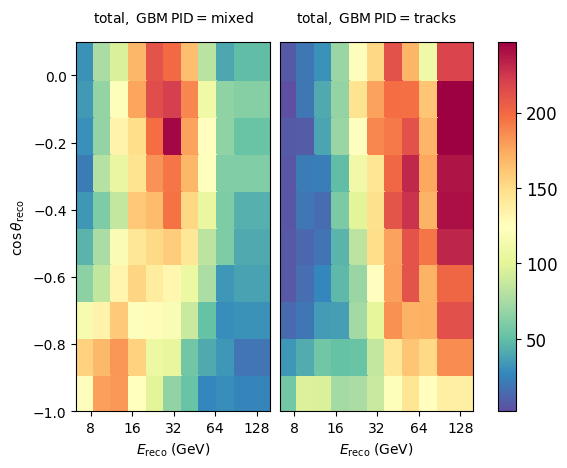

In [23]:
data.plot()

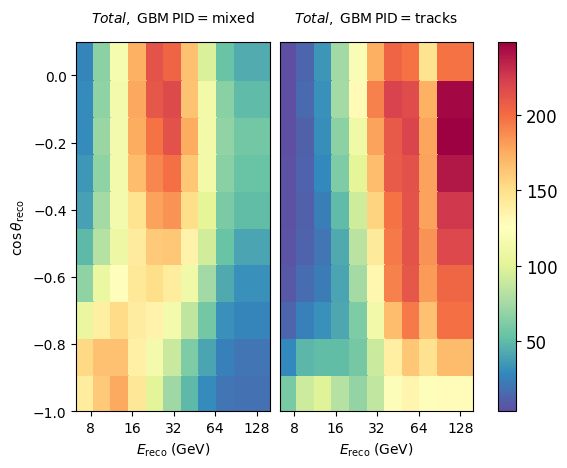

In [24]:
template = model.get_outputs(return_sum=True)
template.plot()

Let's see how good that fit looks like. We here construct signed mod_chi2 maps by hand.
You can see that after the fit, it improved considerably, and the distribution of chi2 values is now more uniform - not much features can be seen anymore.

[ WARNING] /home/jp/software/pisa/pisa/core/map.py:1909: FutureWarning: AffineScalarFunc.__abs__() is deprecated. It will be removed in a future release.
  'hist': np.abs(self.hist)



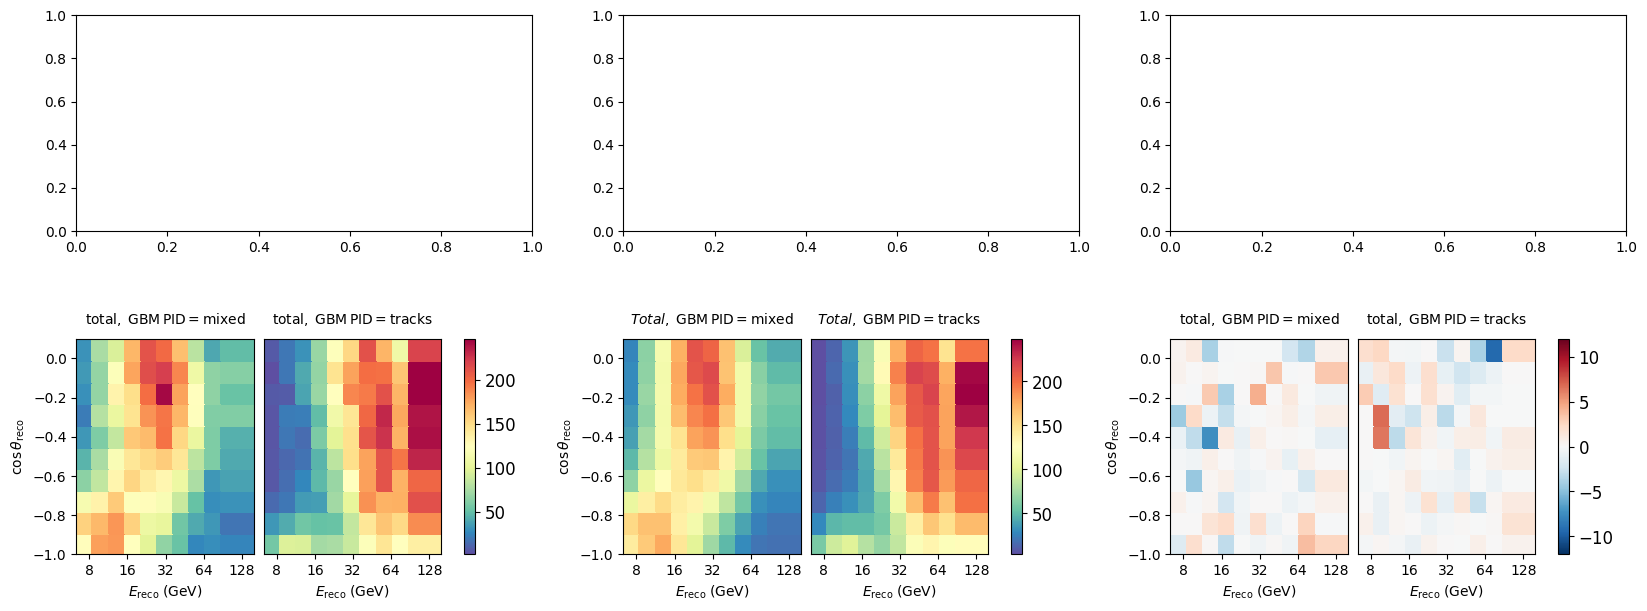

In [25]:
fig, ax = plt.subplots(2, 3, figsize=(20, 7))
plt.subplots_adjust(hspace=0.5)

bestfit = model.get_outputs(return_sum=True)

# data.plot(ax=ax[0,0],title="Data", full_ax=ax[0,0])
# nominal.plot(ax=ax[0,1], full_ax=ax[0,1], title="Nominal")
# diff = data - nominal
# (abs(diff)*diff/(nominal + unp.std_devs(nominal.hist['total']))).plot(ax=ax[0,2], full_ax=ax[0,2],
#                                                                       symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

data.plot(ax=ax[1,0], full_ax=ax[1,0], title="Data")
bestfit.plot(ax=ax[1,1], full_ax=ax[1,1], title="Bestfit")
diff = data - bestfit
(abs(diff)*diff/(bestfit + unp.std_devs(bestfit.hist['total']))).plot(ax=ax[1,2], full_ax=ax[1,2], 
                                                                      symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

When checking the chi2 value from the fitted model, you maybe see that it is around 113, while in the minimizer loop we saw it converged to 116. It is important to keep in mind that in the fit we had extended the metric with prior penalty terms. When we add those back we get the identical number as reported in the fit.

Evaluating other metrics just for fun:

In [26]:
for metric in pisa.utils.stats.ALL_METRICS:
    try:
        print('%s = %.3f'%(metric,data.metric_total(bestfit, metric)))
    except:
        print('%s failed'%metric)

llh = -105.862
conv_llh = -105.191
barlow_llh = -1870.590
mcllh_mean = -729.871
mcllh_eff = -729.842
generalized_poisson_llh failed
chi2 = 212.209
mod_chi2 = 210.801
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__ge__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__le__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

correct_chi2 = 1091.910
weighted_chi2 failed


Adding prior penalty terms

## Storing the results to a file

Since the fit took a while, it might be useful to store the results to a file. (NB: in this example we use a temp file, but in real life you would of course just use a real pathname instead!)

In [27]:
outdir = '/home/jp/daemonflux/oscillations_release_2023/pisa_results/'
filename = 'daemonflux_full_discsms1.json'
pisa.utils.fileio.to_file(result, outdir+filename)

[ WARNING] Directory "/home/jp/daemonflux/oscillations_release_2023/pisa_results" already exists


To reload, we can read the file. But to get PISA objects back, they need to instantiated

In [28]:
result_reload = pisa.utils.fileio.from_file(temp.name)
bestfit_params = pisa.core.ParamSet(result_reload['params']).free
bestfit_params
temp.close()

NameError: name 'temp' is not defined